# RetailMind AI — Day 8: Explainable Vision

Use Grad-CAM to highlight which image regions influenced the Day 7 ResNet50 product-category prediction. This notebook reuses the saved Day 7 model; it does not train a new model.

## Before starting

Run Day 7 first so one of these model files exists: `models/day7_master_category_resnet50.keras` or `models/day7_master_category_resnet50_notebook.keras`. Keep the matching class-name JSON beside it. The catalog photos should be in `data/fashion-product-images-small/images/` (or its `myntradataset/images/` folder).

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import tensorflow as tf

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "fashion-product-images-small"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "day8_gradcam"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / "styles.csv").is_file():
    DATA_DIR = DATA_DIR / "myntradataset"
IMAGE_DIR = DATA_DIR / "images"
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Product photo folder not found: {IMAGE_DIR}")

model_options = [
    (PROJECT_ROOT / "models" / "day7_master_category_resnet50.keras",
     PROJECT_ROOT / "models" / "day7_master_category_class_names.json"),
    (PROJECT_ROOT / "models" / "day7_master_category_resnet50.keras",
     PROJECT_ROOT / "models" / "day6_master_category_class_names.json"),
    (PROJECT_ROOT / "models" / "day7_master_category_resnet50_notebook.keras",
     PROJECT_ROOT / "models" / "day7_master_category_class_names_notebook.json"),
    (PROJECT_ROOT / "models" / "day7_master_category_resnet50_notebook.keras",
     PROJECT_ROOT / "models" / "day6_master_category_class_names.json"),
]
model_path = None
class_names_path = None
for saved_model, saved_names in model_options:
    if saved_model.is_file() and saved_names.is_file():
        model_path = saved_model
        class_names_path = saved_names
        break
if model_path is None:
    raise FileNotFoundError("Train the Day 7 ResNet50 model first.")

model = tf.keras.models.load_model(model_path)
class_names = json.loads(class_names_path.read_text(encoding="utf-8"))
if model.output_shape[-1] != len(class_names):
    raise ValueError("The model output does not match the saved category names.")

image_height, image_width = model.input_shape[1:3]
backbone = model.get_layer("resnet50")
last_conv_layer = backbone.get_layer("conv5_block3_out")
feature_model = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[last_conv_layer.output, backbone.output],
)
print("Loaded Day 7 model:", model_path.name)
print("Categories:", class_names)

## Make one prediction and its heatmap

Grad-CAM uses the gradients of the predicted category to give higher weights to image features that mattered more to that prediction.

In [ ]:
def explain_image(image_path):
    """Return the predicted category, confidence, image, and Grad-CAM map."""
    image_path = Path(image_path)
    if not image_path.is_absolute():
        image_path = PROJECT_ROOT / image_path
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = tf.keras.utils.load_img(
        image_path,
        target_size=(image_height, image_width),
        color_mode="rgb",
    )
    image = tf.keras.utils.img_to_array(image)
    display_image = image / 255.0
    model_image = tf.keras.applications.resnet50.preprocess_input(
        tf.expand_dims(image, axis=0)
    )

    with tf.GradientTape() as tape:
        conv_outputs, backbone_features = feature_model(
            [model_image], training=False
        )
        tape.watch(conv_outputs)
        predictions = backbone_features
        for layer in model.layers[2:]:
            predictions = layer(predictions, training=False)
        predicted_index = int(tf.argmax(predictions[0]).numpy())
        class_score = predictions[:, predicted_index]

    gradients = tape.gradient(class_score, conv_outputs)
    if gradients is None:
        raise ValueError("Could not calculate Grad-CAM gradients.")

    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_outputs[0] * channel_weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (image_height, image_width)
    )[..., 0]

    return {
        "image": display_image,
        "heatmap": heatmap,
        "predicted_category": class_names[predicted_index],
        "confidence": float(predictions[0, predicted_index].numpy()),
    }


## Look at a few catalog photos

The heatmap uses warmer colors for regions with stronger influence. Its overlay is a visual aid, not a guarantee that the model understood the product correctly.

In [ ]:
image_paths = sorted(IMAGE_DIR.glob("*.jpg"))[:3]
if not image_paths:
    raise FileNotFoundError(f"No JPG product photos found in {IMAGE_DIR}")

for image_path in image_paths:
    result = explain_image(image_path)
    figure, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(result["image"])
    axes[0].set_title("Product photo")
    axes[1].imshow(result["image"])
    axes[1].imshow(result["heatmap"], cmap="jet", alpha=0.4)
    axes[1].set_title("Grad-CAM overlay")
    for axis in axes:
        axis.axis("off")
    figure.suptitle(
        f"{result['predicted_category']} "
        f"({result['confidence']:.1%} confidence)"
    )
    plt.tight_layout()
    output_path = OUTPUT_DIR / f"{image_path.stem}_gradcam.png"
    figure.savefig(output_path, dpi=150, bbox_inches="tight")
    print("Saved visualization:", output_path)
    plt.show()
    plt.close(figure)

## Use the same feature from the Python module

The reusable entry point is `explain_image(image_path)` in `src/day8_explainable_vision.py`. It returns an image, heatmap, predicted category, and confidence; use Matplotlib to display the image and heatmap with the same alpha blend shown above.

## Saved output refresh

This cell displays the saved metrics and figures from `reports/` for this notebook. Training and generation cells are kept intact. Model-heavy workflows could not be rerun here because the required TensorFlow, PyTorch, or Transformers packages are unavailable; opt-in generation cells remain disabled.

Showing saved report artifacts for project day(s): [8]


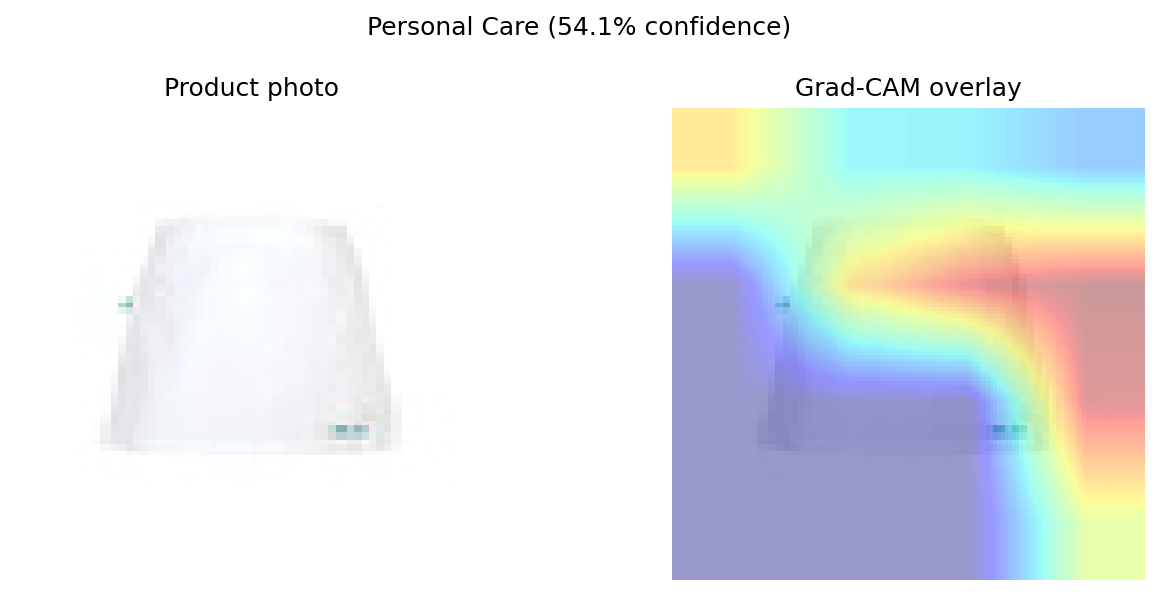

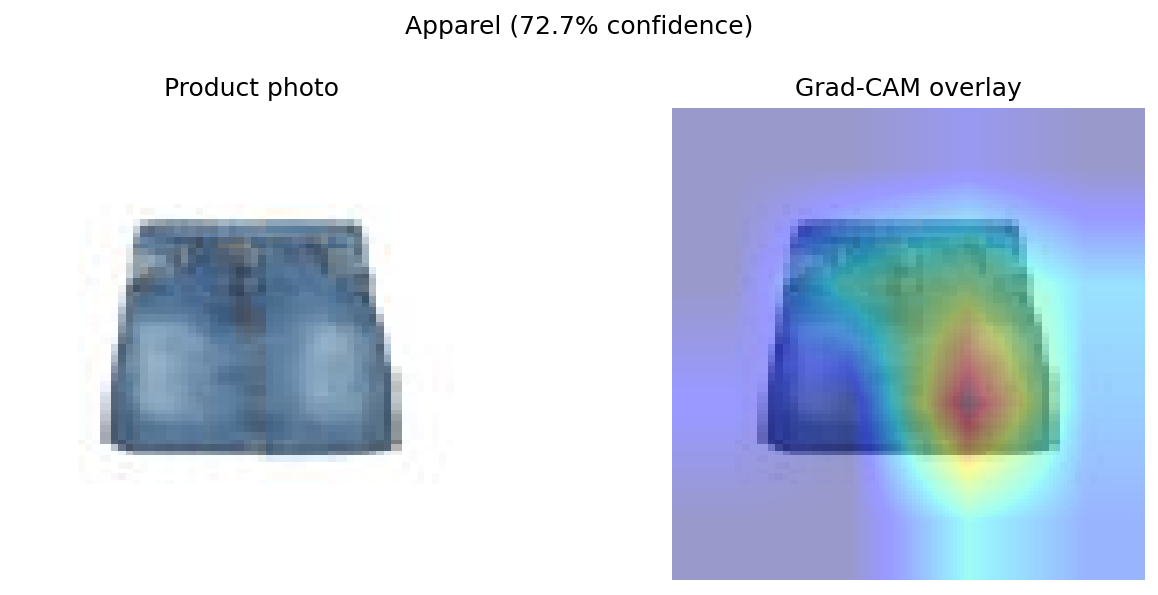

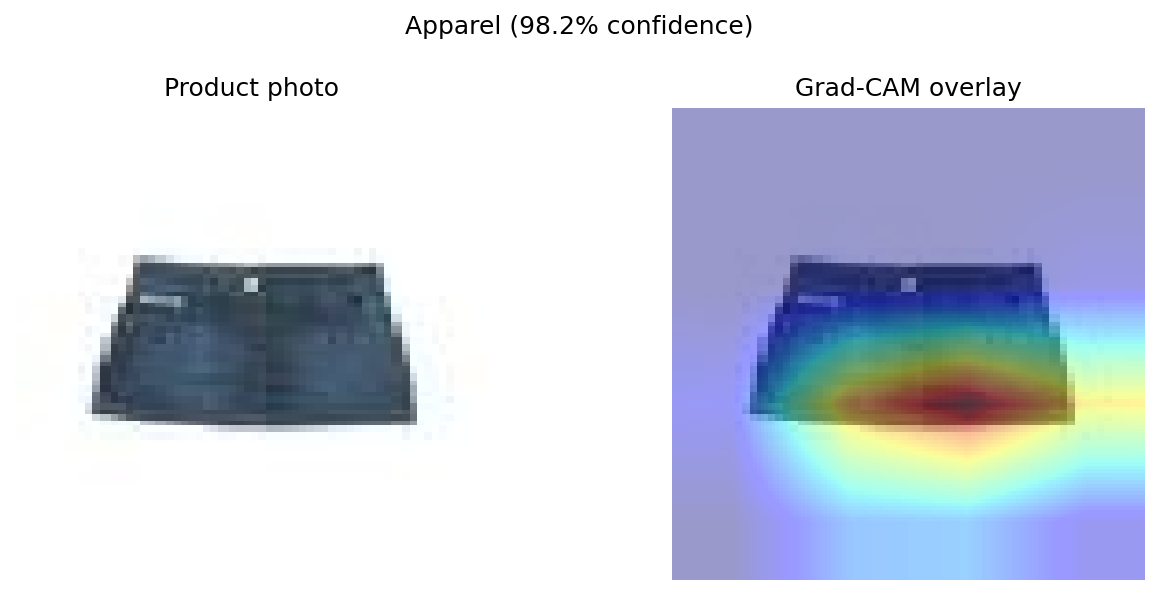

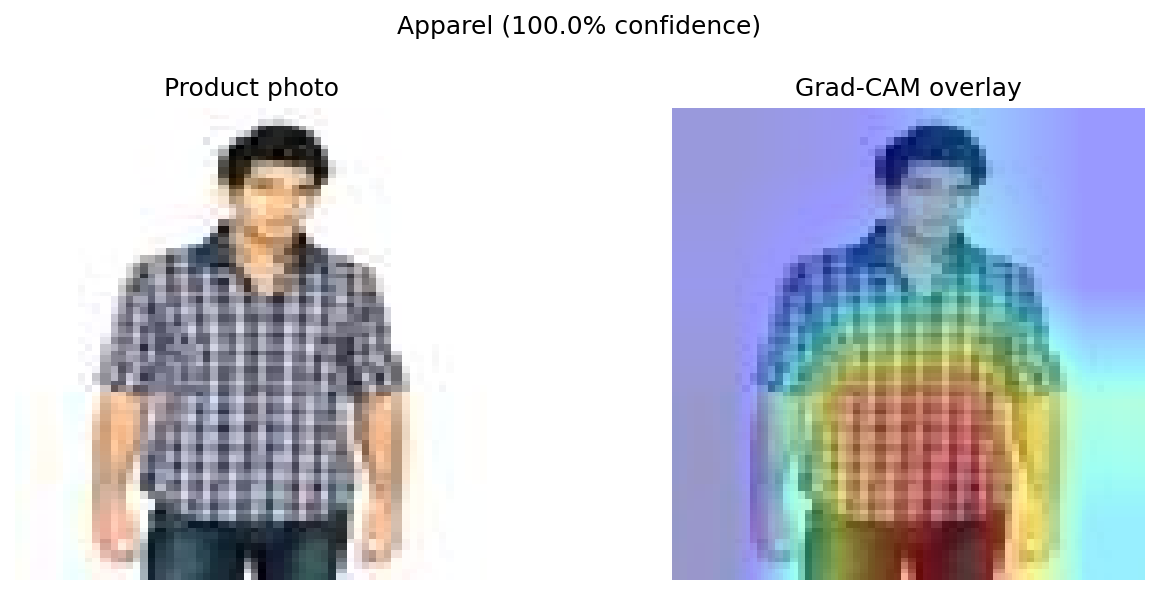

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, SVG, display

# Re-display the saved metrics and figures for this notebook's project day.
# Set ROOT to the repository root if the notebook is launched elsewhere.
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
REPORT_DIR = ROOT / "reports"
DAYS = [8]
print("Showing saved report artifacts for project day(s):", DAYS)
for day in DAYS:
    for path in sorted(REPORT_DIR.glob(f"day{day}*")):
        if path.is_dir():
            for image_path in sorted(path.rglob("*.png")):
                display(Image(filename=str(image_path)))
        elif path.suffix.lower() == ".csv":
            print("\n" + path.name)
            display(pd.read_csv(path, nrows=25))
        elif path.suffix.lower() == ".png":
            display(Image(filename=str(path)))
        elif path.suffix.lower() == ".svg":
            display(SVG(filename=str(path)))
